# Week 2 — House Price Prediction (Linear Regression) & Titanic Survival (Logistic Regression)

**Datasets:**
- [House Prices Dataset (`yasserh/housing-prices-dataset`)](https://www.kaggle.com/datasets/yasserh/housing-prices-dataset)
- [Titanic Dataset (`yasserh/titanic-dataset`)](https://www.kaggle.com/datasets/yasserh/titanic-dataset)

This notebook covers:
1. **Assignment 1 & Mini Project 2**: Build & evaluate a leak-free Linear Regression pipeline for House Price Prediction ($R^2$, Adjusted $R^2$, RMSE, MAE, 5-Fold CV $R^2$) and plot **Predicted vs. Actual** values.
2. **Assignment 2**: Train & evaluate Logistic Regression on the Titanic dataset (Accuracy, ROC-AUC, Confusion Matrix, ROC Curve).

In [1]:
import pandas as pd
from IPython.display import Image, display

from week2_models import (
    HOUSING_PRED_CSV_PATH,
    load_housing_dataset,
    load_titanic_dataset,
    plot_predicted_vs_actual,
    plot_titanic_logistic,
    train_and_evaluate_housing,
    train_and_evaluate_titanic_logistic,
)

## Assignment 1 & Mini Project 2: House Price Prediction (Linear Regression)

In [2]:
df_housing = load_housing_dataset()
print(f"Housing Dataset Shape: {df_housing.shape}")
display(df_housing.head())
display(df_housing.describe().round(2))

Housing Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


,price,area,bedrooms,bathrooms,stories,parking
count,545.00,545.00,545.00,545.00,545.00,545.00
mean,4766729.25,5150.54,2.97,1.29,1.81,0.69
std,1870439.62,2170.14,0.74,0.50,0.87,0.86
min,1750000.00,1650.00,1.00,1.00,1.00,0.00
25%,3430000.00,3600.00,2.00,1.00,1.00,0.00
50%,4340000.00,4600.00,3.00,1.00,2.00,0.00
75%,5740000.00,6360.00,3.00,2.00,2.00,1.00
max,13300000.00,16200.00,6.00,4.00,4.00,3.00


In [3]:
housing_res = train_and_evaluate_housing(df_housing)
print(f"Train R^2        : {housing_res['r2_train']:.4f}")
print(f"Test R^2         : {housing_res['r2_test']:.4f}")
print(f"Adjusted Test R^2: {housing_res['adj_r2_test']:.4f}")
print(f"5-Fold CV R^2    : {housing_res['cv_r2_mean']:.4f} +/- {housing_res['cv_r2_std']:.4f}")
print(f"Test RMSE        : {housing_res['rmse_test']:,.2f}")
print(f"Test MAE         : {housing_res['mae_test']:,.2f}")

HOUSING_PRED_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
housing_res["predictions_df"].to_csv(HOUSING_PRED_CSV_PATH, index=False)
display(housing_res["predictions_df"].head(10))
display(housing_res["coefficients_df"])

Train R^2        : 0.6859
Test R^2         : 0.6529
Adjusted Test R^2: 0.6054
5-Fold CV R^2    : 0.6490 +/- 0.0452
Test RMSE        : 1,324,506.96
Test MAE         : 970,043.40


,Actual_Price,Predicted_Price,Residual,Abs_Error,Pct_Error
0,4060000.0,5164653.90,-1104653.90,1104653.90,27.21
1,6650000.0,7224722.30,-574722.30,574722.30,8.64
2,3710000.0,3109863.24,600136.76,600136.76,16.18
3,6440000.0,4612075.33,1827924.67,1827924.67,28.38
4,2800000.0,3294646.26,-494646.26,494646.26,17.67
5,4900000.0,3532275.10,1367724.90,1367724.90,27.91
6,5250000.0,5611774.57,-361774.57,361774.57,6.89
7,4543000.0,6368145.99,-1825145.99,1825145.99,40.17
8,2450000.0,2722856.96,-272856.96,272856.96,11.14
9,3353000.0,2629405.62,723594.38,723594.38,21.58


,Feature,Coefficient
0,airconditioning_yes,791426.74
1,hotwaterheating_yes,684649.89
2,prefarea_yes,629890.57
3,bathrooms,521879.03
4,area,519552.42
5,furnishingstatus_unfurnished,-413645.06
6,basement_yes,390251.18
7,mainroad_yes,367919.95
8,stories,349251.44
9,guestroom_yes,231610.04


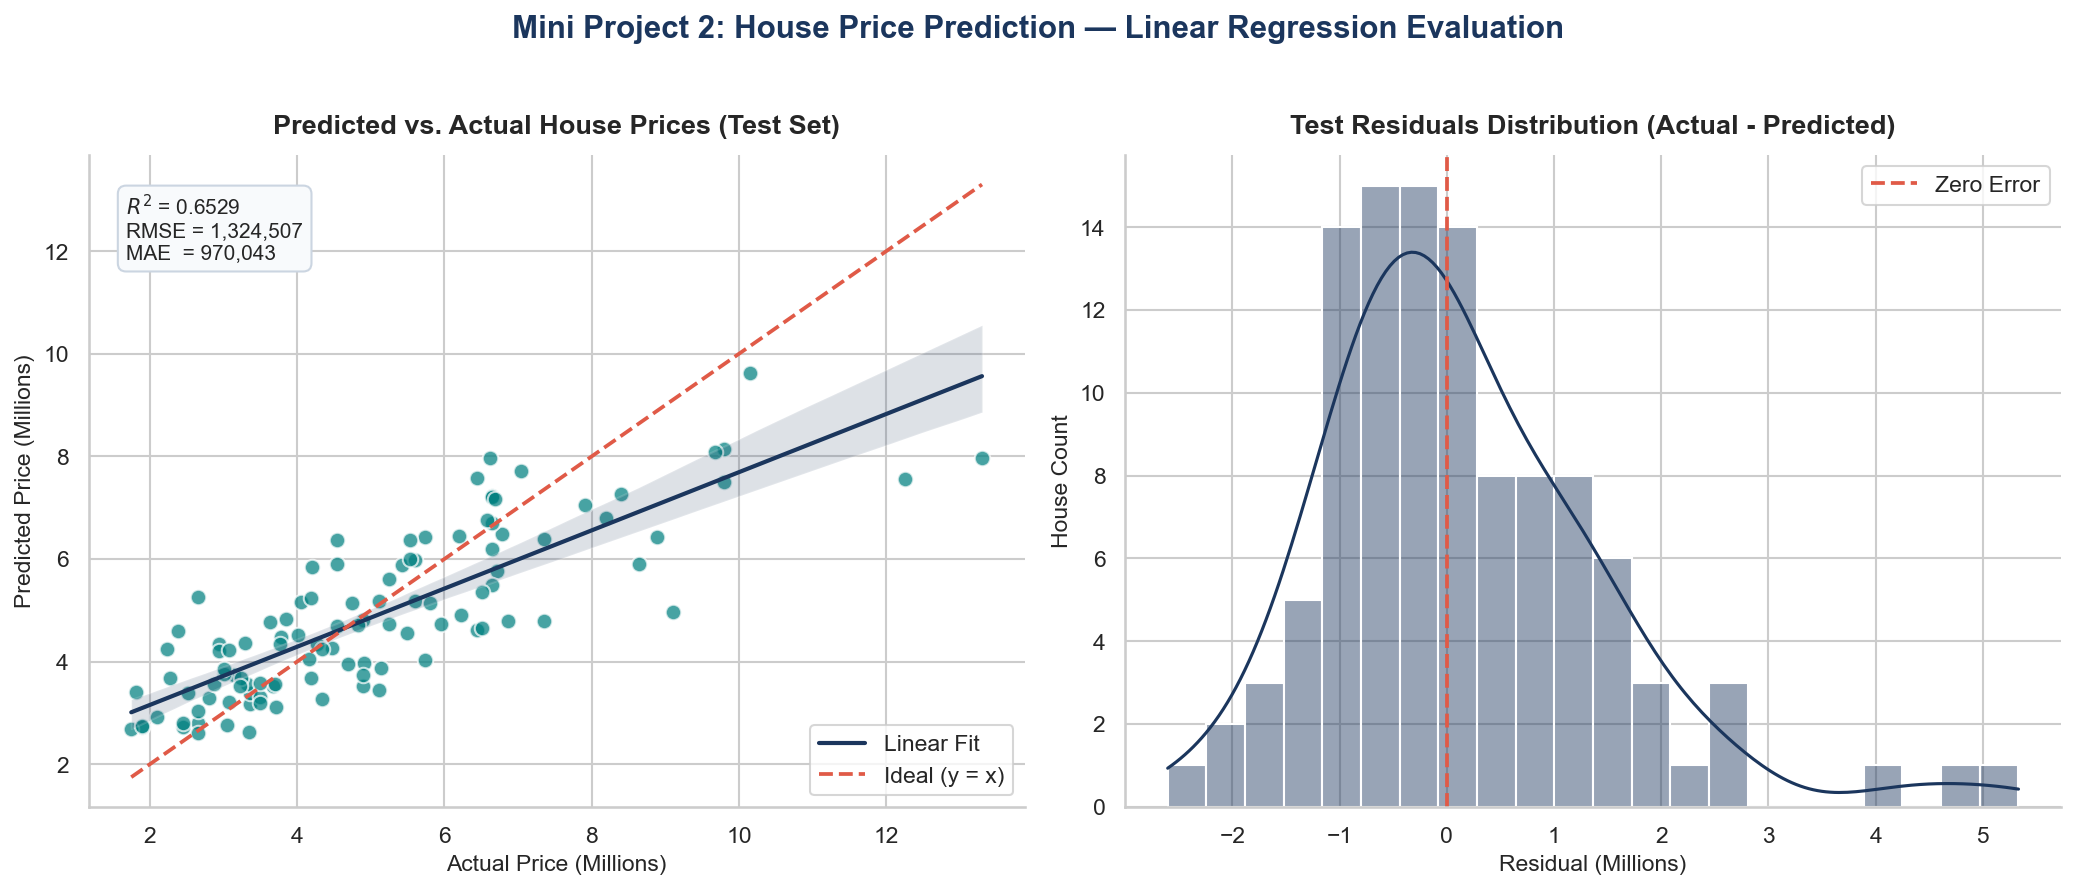

In [4]:
plot_predicted_vs_actual(housing_res)
display(Image(filename="outputs/predicted_vs_actual.png"))

## Assignment 2: Titanic Survival Prediction (Logistic Regression)

5-Fold CV Accuracy: 0.7992 +/- 0.0277
Holdout Accuracy  : 0.8101
Holdout ROC-AUC   : 0.8402

                 precision    recall  f1-score   support

Did Not Survive       0.83      0.87      0.85       110
       Survived       0.78      0.71      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.80       179
   weighted avg       0.81      0.81      0.81       179



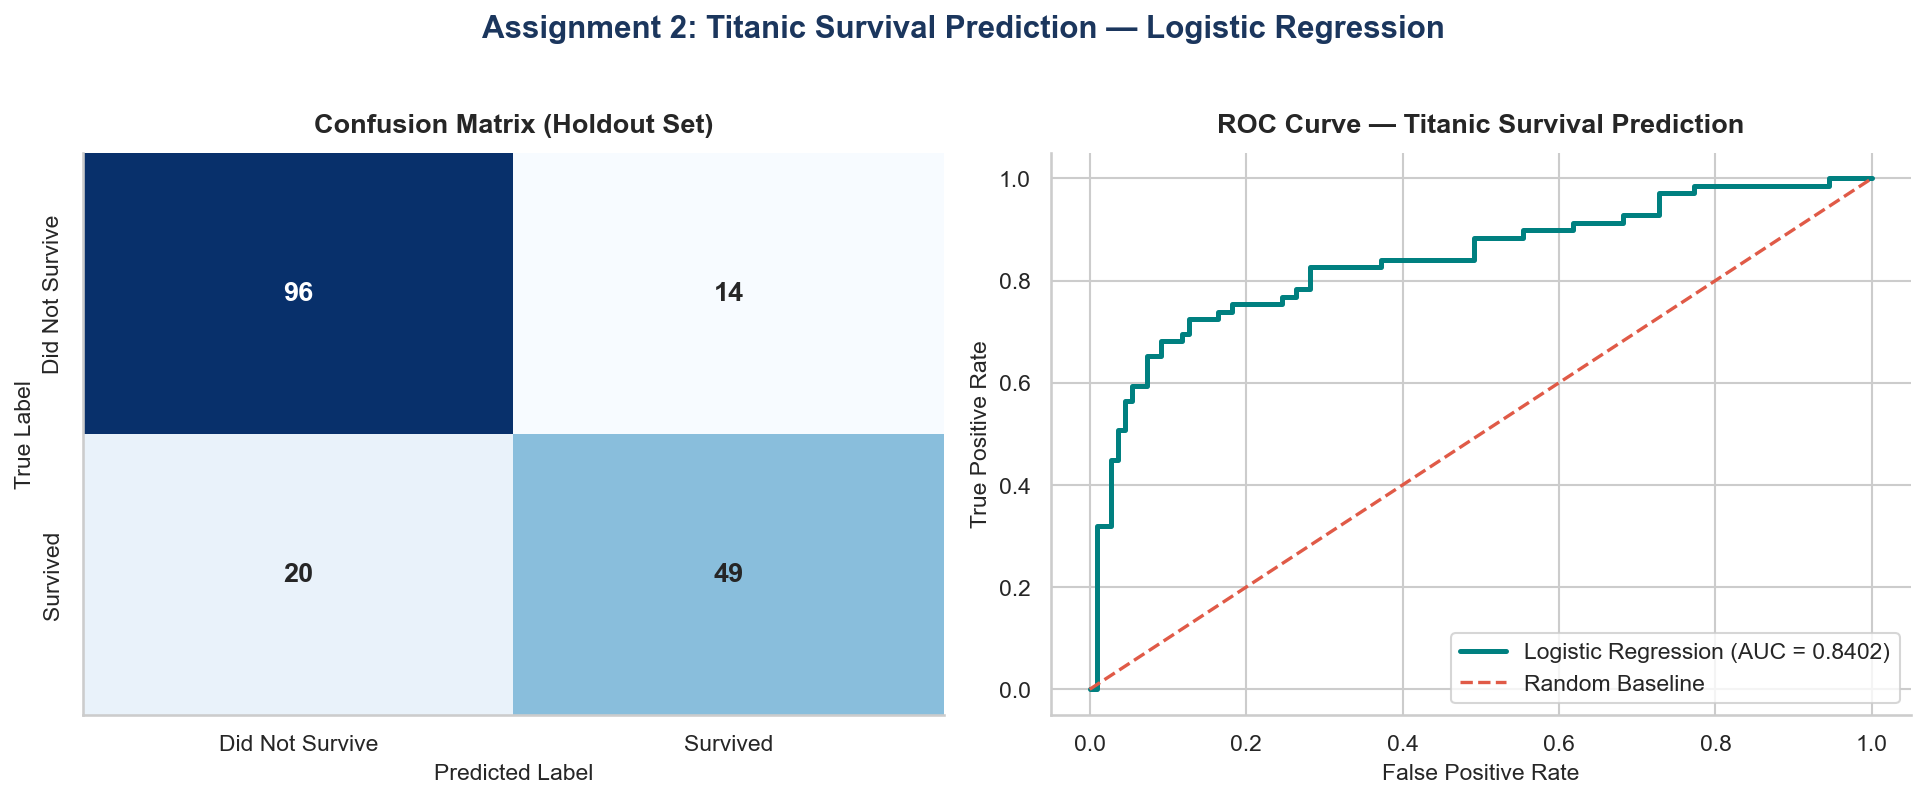

In [5]:
df_titanic = load_titanic_dataset()
titanic_res = train_and_evaluate_titanic_logistic(df_titanic)
print(f"5-Fold CV Accuracy: {titanic_res['cv_accuracy_mean']:.4f} +/- {titanic_res['cv_accuracy_std']:.4f}")
print(f"Holdout Accuracy  : {titanic_res['test_accuracy']:.4f}")
print(f"Holdout ROC-AUC   : {titanic_res['test_roc_auc']:.4f}")
print("\n" + titanic_res["classification_report"])

plot_titanic_logistic(titanic_res)
display(Image(filename="outputs/titanic_logistic_eval.png"))